In [1]:
import os, sys, time
print("=== PUDDLERISK 10% FINAL V3 BOOT ===", flush=True)
print("[BOOT] Python:", sys.version, flush=True)
print("[BOOT] cwd:", os.getcwd(), flush=True)
print("[BOOT] heartbeat 1", flush=True); time.sleep(1)
print("[BOOT] heartbeat 2", flush=True)
open("/kaggle/working/PUDDLERISK_FINAL_V3_STARTED.txt","w").write("started\n")
print("=== HEARTBEAT OK ===", flush=True)

=== PUDDLERISK 10% FINAL V3 BOOT ===
[BOOT] Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
[BOOT] cwd: /kaggle/working
[BOOT] heartbeat 1
[BOOT] heartbeat 2
=== HEARTBEAT OK ===


# 10% — PuddleRisk FINAL v3
## Data-Centric Puddle Surface Instance Segmentation

Final scope: **puddle surface instance segmentation from still road images**.

This notebook does not claim puddle depth, flood severity, hydroplaning probability, accident risk, or geographic risk mapping.

Why v3: v2 only improved Mask mAP50-95 from **0.4039 → 0.4088**, so the final attempt focuses on dataset quality rather than brute-force model scaling.

In [2]:
import importlib.util, subprocess
need=[]
if importlib.util.find_spec("ultralytics") is None: need.append("ultralytics>=8.4.0")
if importlib.util.find_spec("yaml") is None: need.append("pyyaml")
if need: subprocess.check_call([sys.executable,"-m","pip","install","-q",*need])

from pathlib import Path
from collections import defaultdict
import hashlib, json, random, shutil
import numpy as np, pandas as pd, yaml, torch
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
from ultralytics import YOLO

SEED=42
random.seed(SEED); np.random.seed(SEED)
DATA=Path("/kaggle/input/datasets/loliwibu/puddle")
WORK=Path("/kaggle/working/puddlerisk_10pct_final_v3")
CLEAN=WORK/"dataset_clean"; REPORT=WORK/"reports"; ASSET=WORK/"assets"; MODEL=WORK/"models"; RUNS=WORK/"runs"
for p in [WORK,REPORT,ASSET,MODEL,RUNS]: p.mkdir(parents=True,exist_ok=True)
DEVICE=0 if torch.cuda.is_available() else "cpu"
IMG_EXTS={".jpg",".jpeg",".png",".bmp",".webp"}
assert DATA.exists(), DATA
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 47.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 5.6 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
GPU: Tesla T4


## 1. Full dataset + annotation audit

In [3]:
def imgs(split,root=DATA):
    d=root/split/"images"
    return sorted([p for p in d.iterdir() if p.suffix.lower() in IMG_EXTS]) if d.exists() else []
def labs(split,root=DATA):
    d=root/split/"labels"
    return sorted(d.glob("*.txt")) if d.exists() else []
def lab_for(img):
    return img.parent.parent/"labels"/f"{img.stem}.txt"
def parse_label(p):
    txt=p.read_text(errors="ignore").strip()
    if not txt: return []
    out=[]
    for no,line in enumerate(txt.splitlines(),1):
        parts=line.split(); kind="malformed"; cid=None; pts=None
        try:
            vals=[float(x) for x in parts]; cid=int(vals[0])
            if len(vals)==5: kind="bbox"; pts=2
            elif len(vals)>=7 and len(vals)%2==1: kind="polygon"; pts=(len(vals)-1)//2
        except: pass
        out.append(dict(path=str(p),line=no,kind=kind,class_id=cid,points=pts,raw=line))
    return out

ann=[]; empty=[]
for split in ["train","valid"]:
    for lp in labs(split):
        rows=parse_label(lp)
        if not rows: empty.append({"split":split,"path":str(lp)})
        for r in rows: r["split"]=split; ann.append(r)
ann_df=pd.DataFrame(ann)
print("train images:",len(imgs("train")),"valid images:",len(imgs("valid")),"test:",len(imgs("test")))
display(pd.crosstab(ann_df["split"],ann_df["kind"]))
print("empty labels:",pd.DataFrame(empty).groupby("split").size().to_dict())

train images: 1182 valid images: 293 test: 0


kind,bbox,polygon
split,,
train,0,1597
valid,1,375


empty labels: {'train': 19, 'valid': 5}


## 2. Image integrity + exact/near-duplicate leakage audit

In [4]:
def md5(p):
    h=hashlib.md5()
    with open(p,"rb") as f:
        for b in iter(lambda:f.read(1<<20),b""): h.update(b)
    return h.hexdigest()
def dhash64(p):
    with Image.open(p) as im:
        a=np.asarray(ImageOps.exif_transpose(im).convert("L").resize((9,8),Image.Resampling.LANCZOS))
    bits=(a[:,1:]>a[:,:-1]).ravel(); v=0
    for bit in bits: v=(v<<1)|int(bit)
    return v
def ham(a,b): return (a^b).bit_count()

image_rows=[]; by_md5=defaultdict(list)
for split in ["train","valid"]:
    for p in imgs(split):
        unread=False; w=h=None
        try:
            with Image.open(p) as im: im.verify()
            with Image.open(p) as im: w,h=im.size
        except: unread=True
        digest=None if unread else md5(p)
        image_rows.append(dict(split=split,path=str(p),width=w,height=h,unreadable=unread,md5=digest))
        if digest: by_md5[digest].append((split,p))
image_df=pd.DataFrame(image_rows)
print("unreadable:",int(image_df.unreadable.sum()))

exact_cross=[]
for digest,items in by_md5.items():
    if len({s for s,_ in items})>1: exact_cross.append((digest,items))
print("exact cross-split duplicate hashes:",len(exact_cross))

train_h=[(p,dhash64(p)) for p in imgs("train")]
near=[]
for vp in imgs("valid"):
    vh=dhash64(vp); best=(65,None)
    for tp,th in train_h:
        d=ham(vh,th)
        if d<best[0]: best=(d,tp)
        if d==0: break
    if best[0] <= 2:
        near.append({"valid_path":str(vp),"train_path":str(best[1]),"hamming_distance":best[0]})
near_df=pd.DataFrame(near)
print("near-duplicate validation candidates (dHash <=2):",len(near_df))
display(near_df.head(30) if len(near_df) else near_df)
near_df.to_csv(REPORT/"near_duplicate_candidates.csv",index=False)

unreadable: 0
exact cross-split duplicate hashes: 1
near-duplicate validation candidates (dHash <=2): 6


,valid_path,train_path,hamming_distance
0,/kaggle/input/datasets/loliwibu/puddle/valid/i...,/kaggle/input/datasets/loliwibu/puddle/train/i...,0
1,/kaggle/input/datasets/loliwibu/puddle/valid/i...,/kaggle/input/datasets/loliwibu/puddle/train/i...,0
2,/kaggle/input/datasets/loliwibu/puddle/valid/i...,/kaggle/input/datasets/loliwibu/puddle/train/i...,1
3,/kaggle/input/datasets/loliwibu/puddle/valid/i...,/kaggle/input/datasets/loliwibu/puddle/train/i...,0
4,/kaggle/input/datasets/loliwibu/puddle/valid/i...,/kaggle/input/datasets/loliwibu/puddle/train/i...,2
5,/kaggle/input/datasets/loliwibu/puddle/valid/i...,/kaggle/input/datasets/loliwibu/puddle/train/i...,0


## 3. Polygon geometry audit — report extremes, do not delete valid small/large puddles blindly

In [5]:
def poly_area(coords):
    pts=np.asarray(coords,float).reshape(-1,2); x,y=pts[:,0],pts[:,1]
    return .5*abs(np.dot(x,np.roll(y,1))-np.dot(y,np.roll(x,1)))

geom=[]; invalid=[]
for split in ["train","valid"]:
    for lp in labs(split):
        txt=lp.read_text(errors="ignore").strip()
        if not txt: continue
        for no,line in enumerate(txt.splitlines(),1):
            try: vals=[float(x) for x in line.split()]
            except: continue
            if len(vals)>=7 and len(vals)%2==1:
                co=np.asarray(vals[1:]); ok=bool(np.all((co>=0)&(co<=1))); area=poly_area(vals[1:])
                row=dict(split=split,path=str(lp),line=no,points=(len(vals)-1)//2,area_pct=area*100,coords_ok=ok)
                geom.append(row)
                if not ok: invalid.append(row)
geom_df=pd.DataFrame(geom)
display(geom_df.groupby("split")[["points","area_pct"]].describe())
print("out-of-range polygon rows:",len(invalid))
geom_df["tiny_flag"]=geom_df.area_pct<0.01
geom_df["huge_flag"]=geom_df.area_pct>95
display(geom_df.groupby("split")[["tiny_flag","huge_flag"]].sum())
geom_df.to_csv(REPORT/"polygon_geometry_audit.csv",index=False)

points                                                     area_pct  \
        count       mean        std  min   25%   50%   75%    max    count   
split                                                                        
train  1597.0  26.978710  18.611065  4.0  13.0  22.0  35.0  127.0   1597.0   
valid   375.0  27.501333  19.450042  4.0  14.0  22.0  35.0  140.0    375.0   

                                                                       \
            mean        std       min       25%        50%        75%   
split                                                                   
train  17.873535  18.791520  0.003147  3.670253  11.589475  26.018877   
valid  17.082010  17.607958  0.083749  3.064941  10.869138  25.935049   

                  
             max  
split             
train  95.784253  
valid  90.692758

out-of-range polygon rows: 0


,tiny_flag,huge_flag
split,,
train,1,1
valid,0,0


## 4. Conservative cleaning

Automatically exclude only defensible problems:

**Validation**
- unreadable images;
- exact train duplicates;
- dHash near-duplicates with distance ≤ 2;
- positive bbox/malformed labels inside the segmentation dataset;
- out-of-range polygon coordinates.

**Training**
- unreadable images;
- positive bbox/malformed labels;
- out-of-range polygon coordinates.

Empty labels stay as legitimate negatives. Geometry extremes are only reported.

In [6]:
bad_tr=set(); bad_va=set(); reasons=[]

for _,r in image_df.iterrows():
    if r.unreadable:
        p=Path(r.path).resolve(); (bad_tr if r.split=="train" else bad_va).add(p)
        reasons.append({"split":r.split,"path":str(p),"reason":"unreadable"})

for _,items in exact_cross:
    for split,p in items:
        if split=="valid":
            bad_va.add(p.resolve()); reasons.append({"split":"valid","path":str(p.resolve()),"reason":"exact_train_duplicate"})

for _,r in near_df.iterrows():
    p=Path(r.valid_path).resolve(); bad_va.add(p)
    reasons.append({"split":"valid","path":str(p),"reason":f"near_train_duplicate_dhash_{int(r.hamming_distance)}"})

for _,r in ann_df[ann_df.kind!="polygon"].iterrows():
    lp=Path(r.path); split=r["split"]
    for p in (lp.parent.parent/"images").glob(lp.stem+".*"):
        if p.suffix.lower() in IMG_EXTS:
            q=p.resolve(); (bad_tr if split=="train" else bad_va).add(q)
            reasons.append({"split":split,"path":str(q),"reason":f"annotation_{r.kind}"})

for r in invalid:
    lp=Path(r["path"]); split=r["split"]
    for p in (lp.parent.parent/"images").glob(lp.stem+".*"):
        if p.suffix.lower() in IMG_EXTS:
            q=p.resolve(); (bad_tr if split=="train" else bad_va).add(q)
            reasons.append({"split":split,"path":str(q),"reason":"coords_out_of_range"})

clean_tr=[p for p in imgs("train") if p.resolve() not in bad_tr]
clean_va=[p for p in imgs("valid") if p.resolve() not in bad_va]
summary={"original_train":len(imgs("train")),"clean_train":len(clean_tr),"excluded_train":len(bad_tr),
         "original_valid":len(imgs("valid")),"clean_valid":len(clean_va),"excluded_valid":len(bad_va)}
print(json.dumps(summary,indent=2))
pd.DataFrame(reasons).drop_duplicates().to_csv(REPORT/"cleaning_exclusions.csv",index=False)

{
  "original_train": 1182,
  "clean_train": 1182,
  "excluded_train": 0,
  "original_valid": 293,
  "clean_valid": 286,
  "excluded_valid": 7
}


## 5. Build writable clean dataset

In [7]:
if CLEAN.exists(): shutil.rmtree(CLEAN)
for split in ["train","valid"]:
    (CLEAN/split/"images").mkdir(parents=True,exist_ok=True); (CLEAN/split/"labels").mkdir(parents=True,exist_ok=True)

def cp_pair(p,split):
    shutil.copy2(p,CLEAN/split/"images"/p.name)
    lp=lab_for(p)
    if lp.exists(): shutil.copy2(lp,CLEAN/split/"labels"/lp.name)

for p in clean_tr: cp_pair(p,"train")
for p in clean_va: cp_pair(p,"valid")

yaml_path=WORK/"puddle_final_clean.yaml"
yaml_path.write_text(yaml.safe_dump({"path":str(CLEAN),"train":"train/images","val":"valid/images","nc":1,"names":["puddle"]},sort_keys=False))
print(yaml_path.read_text())

path: /kaggle/working/puddlerisk_10pct_final_v3/dataset_clean
train: train/images
val: valid/images
nc: 1
names:
- puddle



## 6. FINAL training — YOLO11s-seg @ 640

Controlled final run:
- pretrained YOLO11s-seg;
- 640 input;
- AdamW;
- cosine LR;
- moderate puddle-aware augmentation;
- maximum 140 epochs;
- early stopping patience 30;
- primary metric: **Mask mAP50-95**.

In [8]:
model=YOLO("yolo11s-seg.pt")
tr=model.train(
    data=str(yaml_path), epochs=140, imgsz=640, batch=8, device=DEVICE, workers=2,
    patience=30, pretrained=True, optimizer="AdamW", lr0=5e-4, lrf=0.03,
    momentum=0.9, weight_decay=5e-4, cos_lr=True,
    warmup_epochs=5.0, warmup_momentum=0.8, warmup_bias_lr=0.04,
    amp=True, cache="disk", seed=SEED, deterministic=True, plots=True,
    hsv_h=0.006, hsv_s=0.20, hsv_v=0.15,
    degrees=2.0, translate=0.04, scale=0.12, shear=0.0, perspective=0.0,
    fliplr=0.5, flipud=0.0, mosaic=0.15, mixup=0.0, copy_paste=0.0, close_mosaic=20,
    project=str(RUNS), name="puddlerisk_final_v3", exist_ok=True, verbose=True
)
train_dir=Path(tr.save_dir); best_pt=train_dir/"weights"/"best.pt"; last_pt=train_dir/"weights"/"last.pt"
assert best_pt.exists()
print("[BEST]",best_pt)

Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=disk, cfg=None, channels_last=None, classes=None, close_mosaic=20, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/puddlerisk_10pct_final_v3/puddle_final_clean.yaml, degrees=2.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=140, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.006, hsv_s=0.2, hsv_v=0.15, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.03, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s-seg.pt, momentum=0.9, mosaic=0.15, multi_scale=0.0, name=puddlerisk_final_v3,

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


      2/140      3.03G      1.475      2.906      1.548      1.877          0         10        640: 100% ━━━━━━━━━━━━ 148/148 7.6it/s 19.6s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 5.6it/s 3.2s
                   all        286        369      0.606      0.504      0.547       0.26      0.617      0.474        0.5      0.224

      Epoch    GPU_mem   box_loss   seg_loss   cls_loss   dfl_loss   sem_loss  Instances       Size
      3/140      3.03G      1.522      2.842      1.529      1.897          0          6        640: 100% ━━━━━━━━━━━━ 148/148 7.5it/s 19.7s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 5.6it/s 3.2s
                   all        286        369      0.651      0.545      0.576      0.278       0.66      0.511      0.514       0.23

      Ep

## 7. Final clean-validation metrics

In [9]:
bm=YOLO(str(best_pt))
met=bm.val(data=str(yaml_path),split="val",imgsz=640,batch=8,device=DEVICE,workers=2,
           plots=True,project=str(RUNS),name="final_clean_validation",exist_ok=True,verbose=True)

final_metrics={
 "model":"YOLO11s-seg","input_size":640,"validation_images":len(clean_va),
 "box":{"precision":float(met.box.mp),"recall":float(met.box.mr),"mAP50":float(met.box.map50),"mAP50_95":float(met.box.map)},
 "mask":{"precision":float(met.seg.mp),"recall":float(met.seg.mr),"mAP50":float(met.seg.map50),"mAP50_95":float(met.seg.map)},
 "speed_ms":{k:float(v) for k,v in met.speed.items()}
}
print(json.dumps(final_metrics,indent=2))
(REPORT/"final_validation_metrics.json").write_text(json.dumps(final_metrics,indent=2))

Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s-seg summary (fused): 113 layers, 10,067,203 parameters, 0 gradients, 32.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1115.7±242.7 MB/s, size: 38.3 KB)
val: Scanning /kaggle/working/puddlerisk_10pct_final_v3/dataset_clean/valid/labels.cache... 286 images, 4 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 286/286 120.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 36/36 5.8it/s 6.2s
                   all        286        369      0.814      0.687      0.751      0.455      0.801      0.677      0.738        0.4
Speed: 1.3ms preprocess, 12.6ms inference, 0.0ms loss, 1.7ms postprocess per image
Results saved to /kaggle/working/puddlerisk_10pct_final_v3/runs/final_clean_validation
{
  "model": "YOLO11s-seg",
  "input_size": 640,
  "validation_images": 286,
  "box": {
    "prec

556

## 8. v1 vs v2 vs FINAL v3

In [10]:
cmp=pd.DataFrame([
 {"version":"v1 YOLO11n 416","mask_P":0.7190201493,"mask_R":0.6997319035,"mask_mAP50":0.7255760764,"mask_mAP50_95":0.4039297878},
 {"version":"v2 YOLO11s 640 Stage B","mask_P":0.7645752940,"mask_R":0.6943699732,"mask_mAP50":0.7248195221,"mask_mAP50_95":0.4088462879},
 {"version":"v3 FINAL data-centric","mask_P":final_metrics["mask"]["precision"],"mask_R":final_metrics["mask"]["recall"],
  "mask_mAP50":final_metrics["mask"]["mAP50"],"mask_mAP50_95":final_metrics["mask"]["mAP50_95"]}
])
display(cmp.sort_values("mask_mAP50_95",ascending=False))
cmp.to_csv(REPORT/"version_comparison.csv",index=False)

,version,mask_P,mask_R,mask_mAP50,mask_mAP50_95
1,v2 YOLO11s 640 Stage B,0.764575,0.694370,0.724820,0.408846
0,v1 YOLO11n 416,0.719020,0.699732,0.725576,0.403930
2,v3 FINAL data-centric,0.801083,0.676664,0.738049,0.399750


## 9. Qualitative final prediction grid

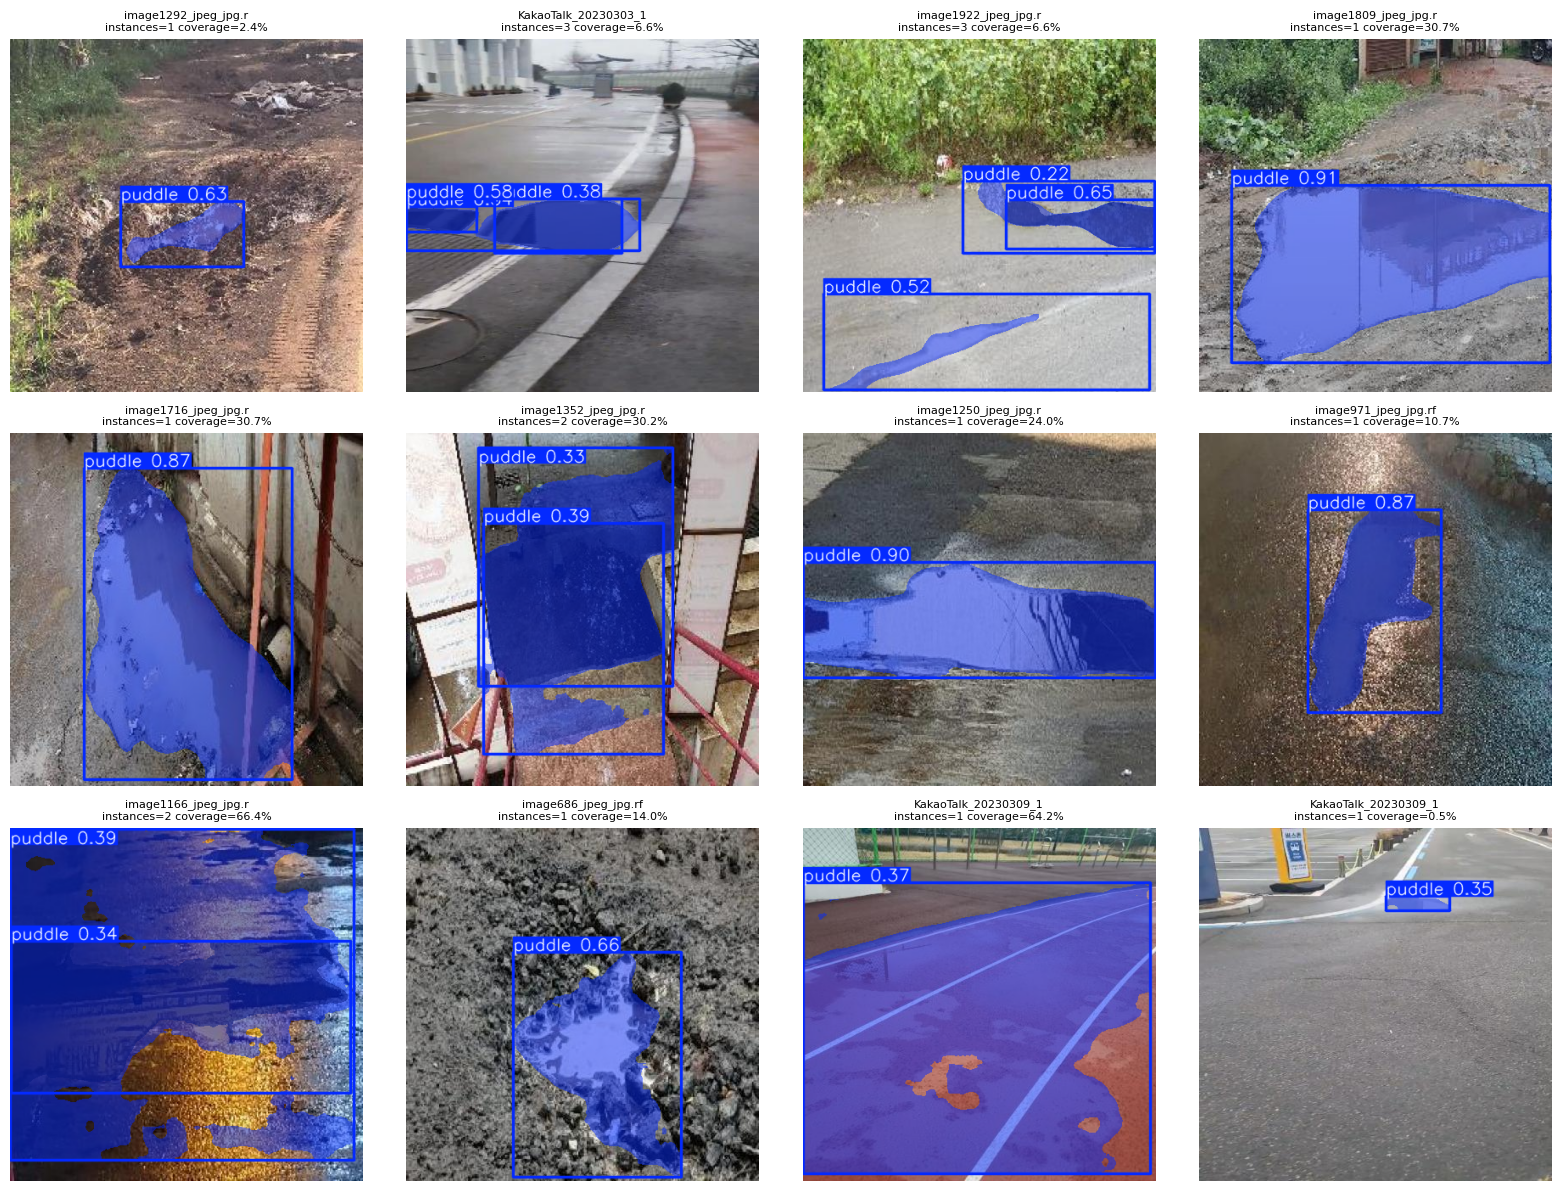

[NOTE] coverage is image-area proxy only, not physical risk/depth.


In [11]:
samples=random.Random(SEED).sample(imgs("valid",CLEAN),k=min(12,len(imgs("valid",CLEAN))))
pred=bm.predict(source=[str(x) for x in samples],imgsz=640,conf=.20,iou=.6,device=DEVICE,retina_masks=True,verbose=False)
fig,axs=plt.subplots(3,4,figsize=(16,12)); rows=[]
for ax,p,r in zip(axs.flat,samples,pred):
    show=r.plot()[:,:,::-1]; n=0; cov=0.0
    if r.masks is not None and r.masks.data is not None and len(r.masks.data):
        stack=r.masks.data.detach().cpu().numpy()>.5; n=int(stack.shape[0]); cov=float(np.any(stack,axis=0).mean()*100)
    rows.append({"image":p.name,"instances":n,"mask_coverage_pct":cov})
    ax.imshow(show); ax.set_title(f"{p.name[:20]}\ninstances={n} coverage={cov:.1f}%",fontsize=8); ax.axis("off")
plt.tight_layout(); out=ASSET/"final_prediction_grid.png"; plt.savefig(out,dpi=170,bbox_inches="tight"); plt.show()
pd.DataFrame(rows).to_csv(REPORT/"final_prediction_preview.csv",index=False)
print("[NOTE] coverage is image-area proxy only, not physical risk/depth.")

## 10. Save final model, reports, plots, and ZIP

In [12]:
final_model=MODEL/"puddlerisk_final_best.pt"; shutil.copy2(best_pt,final_model)
if last_pt.exists(): shutil.copy2(last_pt,MODEL/"puddlerisk_final_last.pt")

for d in [train_dir,Path(met.save_dir)]:
    if d.exists():
        for src in d.glob("*.png"):
            shutil.copy2(src,ASSET/f"{d.name}_{src.name}")

audit={"cleaning":summary,"exact_cross_split_duplicates":len(exact_cross),
       "near_duplicate_candidates":len(near_df),"invalid_polygon_coordinate_rows":len(invalid)}
(REPORT/"final_dataset_audit.json").write_text(json.dumps(audit,indent=2))

score=final_metrics["mask"]["mAP50_95"]; v2=0.4088462879
grade=("VERY STRONG" if score>=.60 else "STRONG" if score>=.50 else
       "MODERATE" if score>=.45 else "IMPROVED" if score>v2 else "DID NOT BEAT V2")
summary_final={"project":"PuddleRisk FINAL v3","validated_task":"puddle surface instance segmentation",
               "quality_gate":grade,"final_metrics":final_metrics,"dataset_audit":audit,
               "claim_limits":["no independent test split","no puddle depth","no flood severity",
                               "no hydroplaning probability","no physical road-risk score","no geospatial map"]}
(REPORT/"final_summary.json").write_text(json.dumps(summary_final,indent=2))
print("[QUALITY GATE]",grade); print(json.dumps(summary_final,indent=2))

zip_path=shutil.make_archive("/kaggle/working/puddlerisk_10pct_FINAL","zip",root_dir=str(WORK))
print("\n=== PUDDLERISK 10% FINAL DONE ===")
print("[DONE] model:",final_model)
print("[DONE] Mask mAP50:",final_metrics["mask"]["mAP50"])
print("[DONE] Mask mAP50-95:",final_metrics["mask"]["mAP50_95"])
print("[DONE] ZIP:",zip_path)

[QUALITY GATE] DID NOT BEAT V2
{
  "project": "PuddleRisk FINAL v3",
  "validated_task": "puddle surface instance segmentation",
  "quality_gate": "DID NOT BEAT V2",
  "final_metrics": {
    "model": "YOLO11s-seg",
    "input_size": 640,
    "validation_images": 286,
    "box": {
      "precision": 0.8138581520364372,
      "recall": 0.6872387724698426,
      "mAP50": 0.7511533909635795,
      "mAP50_95": 0.45541072967139107
    },
    "mask": {
      "precision": 0.8010834218140742,
      "recall": 0.676664331911148,
      "mAP50": 0.738048733561852,
      "mAP50_95": 0.39974950295810374
    },
    "speed_ms": {
      "preprocess": 1.3418902097906868,
      "inference": 12.59949062238355,
      "loss": 0.0016837902033718434,
      "postprocess": 1.7164532657302929
    }
  },
  "dataset_audit": {
    "cleaning": {
      "original_train": 1182,
      "clean_train": 1182,
      "excluded_train": 0,
      "original_valid": 293,
      "clean_valid": 286,
      "excluded_valid": 7
    },
  

# Save Version checklist

- [ ] heartbeat visible
- [ ] audit finished
- [ ] exact + near-duplicate audit finished
- [ ] polygon geometry audit finished
- [ ] clean dataset built
- [ ] final training finished
- [ ] `best.pt` exists
- [ ] clean-validation metrics printed
- [ ] qualitative grid checked
- [ ] comparison report saved
- [ ] final ZIP exists

Expected output:

`/kaggle/working/puddlerisk_10pct_FINAL.zip`

Public claim: **PuddleRisk is a data-audited YOLO11s-seg MVP for puddle-surface instance segmentation. Performance is reported on a cleaned validation split; the source dataset has no independent test split.**